<a href="https://colab.research.google.com/github/imagra93/ML-course-labs/blob/main/notebooks/neural_networks/lab 13 - LSTM sentiment analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab · Sentiment analysis with recurrent neural networks (LSTM)

Images have a fixed size. Text does not: a review can have 10 words or 2,000, and the **order** of the words can matter ("not good, just bad" versus "not bad, just good"). In this lab you classify IMDB movie reviews as **positive** or **negative** with an **LSTM**, a recurrent network that reads the review one word at a time and keeps a memory of what it has read.

We will also be honest about the results: for this task, a simple model that ignores word order is very strong. Comparing against it is part of the job.

**Contents**

1. Setup and data
2. A strong baseline that ignores word order
3. From text to tensors: truncation, padding, lengths
4. The model: Embedding → LSTM → linear
5. Training, with gradient clipping and early stopping
6. Evaluation on the test set
7. Is word order worth modelling?
8. Your own reviews
9. Summary and practical tips

Theory: the slides [RNNs and LSTMs](https://imagra93.github.io/ML-course-labs/slides/neural_networks/05_rnn_lstm.html). The RNN and the LSTM written from scratch, backpropagation through time and more experiments are in the **extended version** of this lab, linked at the end.

A GPU makes training about 10 times faster (in Colab: *Runtime → Change runtime type → T4 GPU*): about 3 minutes with a GPU, 20 to 30 minutes on a CPU.

## 1. Setup and data

The [IMDB dataset](https://ai.stanford.edu/~amaas/data/sentiment/) has 50,000 movie reviews, 25,000 for training and 25,000 for testing, half positive and half negative. We download the version distributed with Keras. Each review is already **tokenised**: lower-cased, punctuation removed, split into words, and each word replaced by its **frequency rank** in the corpus (1 = "the", the most frequent word, 2 = "and", and so on).

In [1]:
import copy, json, os, re, time, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"
cache = os.path.expanduser("~/.cache/imdb_keras")
os.makedirs(cache, exist_ok=True)
for fname in ["imdb.npz", "imdb_word_index.json"]:
    if not os.path.exists(os.path.join(cache, fname)):
        urllib.request.urlretrieve(URL + fname, os.path.join(cache, fname))

raw = np.load(os.path.join(cache, "imdb.npz"), allow_pickle=True)          # a trusted file: it stores Python lists
word_rank = json.load(open(os.path.join(cache, "imdb_word_index.json")))   # word -> frequency rank
print("train reviews:", len(raw["x_train"]), " test reviews:", len(raw["x_test"]), " distinct words:", len(word_rank))

device: cuda


train reviews: 25000  test reviews: 25000  distinct words: 88584


**The vocabulary.** We keep the $V = 10{,}000$ most frequent words, which cover about 94% of the text, and reserve four special indices: `<PAD>` = 0 (padding), `<START>` = 1 (start of a review), `<UNK>` = 2 (any word outside the vocabulary) and 3 (unused). A word of rank $r$ gets index $r + 3$.

**Three sets.** We hold out 5,000 training reviews as a **validation set** for all choices, and keep the 25,000 test reviews for the final evaluation only.

In [2]:
V = 10_000
PAD, START, UNK = 0, 1, 2
word_index = {w: r + 3 for w, r in word_rank.items()}
word_index.update({"<PAD>": PAD, "<START>": START, "<UNK>": UNK, "<UNUSED>": 3})
index_word = {i: w for w, i in word_index.items()}

def encode_ranks(ranks):
    """Frequency ranks -> token indices in [0, V), with <START> first and rare words as <UNK>."""
    return np.array([START] + [r + 3 if r + 3 < V else UNK for r in ranks], dtype=np.int64)

def decode(ids):
    return " ".join(index_word.get(int(i), "?") for i in ids if int(i) != PAD)

rng = np.random.default_rng(0)
perm = rng.permutation(len(raw["x_train"]))                 # the file is sorted by label: shuffle it
seqs_all = [encode_ranks(r) for r in raw["x_train"][perm]]
labels_all = raw["y_train"][perm]
seqs_val, y_val = seqs_all[:5000], labels_all[:5000]
seqs_tr, y_tr = seqs_all[5000:], labels_all[5000:]
seqs_te, y_te = [encode_ranks(r) for r in raw["x_test"]], raw["y_test"]
class_names = ["Negative", "Positive"]

print(f"train {len(seqs_tr)}, validation {len(seqs_val)}, test {len(seqs_te)};  fraction positive {y_tr.mean():.2f}")
print("\nexample review, as indices:", seqs_tr[0][:12], "...")
print("decoded:", decode(seqs_tr[0])[:400], "...")
print("label:", class_names[y_tr[0]])
lengths = np.array([len(s) for s in seqs_tr])
print(f"\nreview length: median {np.median(lengths):.0f} tokens, 90% are shorter than {np.percentile(lengths, 90):.0f}, max {lengths.max()}")

train 20000, validation 5000, test 25000;  fraction positive 0.50

example review, as indices: [   1 1100    5 4434  185 4545    2    6    2    2    5 5755] ...
decoded: <START> bored and unhappy young babe <UNK> a <UNK> <UNK> and vibrant performance by <UNK> brunette <UNK> erika anderson feels trapped in a stale and <UNK> marriage to failed poet and decent yet dull businessman <UNK> martin a solid and credible portrayal by judge <UNK> <UNK> has a <UNK> <UNK> <UNK> with sleazy and arrogant artist johnny collins deliciously played to the slimy <UNK> by nicolas cage ...
label: Positive

review length: median 178 tokens, 90% are shorter than 467, max 2494


The `br` you may see in the reviews comes from HTML line breaks `<br />` in the original text. Real data is always a little dirty.

## 2. A strong baseline that ignores word order

Before building an LSTM, we should know what a simple model achieves. The classic text baseline is a **bag of words**: describe each review by how often each vocabulary word appears, throw away the order, and fit a logistic regression. **TF-IDF** weighting down-weights the words that appear in almost every review ("the", "movie") and up-weights the distinctive ones. Both tools come from scikit-learn, as in the machine learning labs. Our reviews are lists of integer ids, not strings, so instead of the default tokeniser of the slides we pass `analyzer=`, a function that returns the tokens of a document: here, the ids themselves. Each id then plays the role of a word.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(analyzer=lambda ids: ids.tolist())     # our reviews are already lists of tokens
A_tr, A_val = tfidf.fit_transform(seqs_tr), tfidf.transform(seqs_val)
logreg = LogisticRegression(C=5, max_iter=2000).fit(A_tr, y_tr)
acc_bow_val = logreg.score(A_val, y_val)
print(f"TF-IDF + logistic regression: validation accuracy {acc_bow_val:.4f}")

vocab = np.array(tfidf.get_feature_names_out())
order = np.argsort(logreg.coef_[0])
print("\nmost negative words:", ", ".join(index_word[int(vocab[i])] for i in order[:12]))
print("most positive words:", ", ".join(index_word[int(vocab[i])] for i in order[::-1][:12]))

TF-IDF + logistic regression: validation accuracy 0.8956

most negative words: worst, awful, waste, bad, boring, disappointment, poorly, terrible, horrible, worse, dull, mess
most positive words: 7, great, excellent, perfect, best, 8, wonderful, today, amazing, highly, fun, favorite


Almost 90% without knowing anything about word order, and the weights make sense: "worst" and "waste" are strong negative evidence, "excellent" and "7" (as in "7/10") positive. **Keep this number in mind**: the LSTM has to earn its extra complexity.

## 3. From text to tensors: truncation, padding, lengths

To train in batches, all the sequences in a batch must have the same length $T$:
- **Truncation.** Reviews longer than $T = 200$ tokens are cut. Reviewers often give their verdict at the end ("... overall, 8/10"), so we keep the **last** 200 tokens.
- **Padding.** Shorter reviews are filled with `<PAD>` (index 0) at the end. We also store each review's true **length**, so that the model can ignore the padding.

The result is a tensor of token indices of shape $(N, T)$, plus $N$ lengths and $N$ labels.

In [4]:
T = 200

def to_tensors(seqs, labels, T=T):
    X = np.zeros((len(seqs), T), dtype=np.int64)            # filled with <PAD> = 0
    L = np.zeros(len(seqs), dtype=np.int64)
    for i, s in enumerate(seqs):
        s = s[-T:]                                           # keep the last T tokens
        X[i, :len(s)] = s                                    # pad at the end
        L[i] = len(s)
    return torch.tensor(X), torch.tensor(L), torch.tensor(labels, dtype=torch.float32)

X_tr, L_tr, Y_tr = to_tensors(seqs_tr, y_tr)
X_val, L_val, Y_val = to_tensors(seqs_val, y_val)
X_te, L_te, Y_te = to_tensors(seqs_te, y_te)
print("X_tr:", tuple(X_tr.shape), " L_tr:", tuple(L_tr.shape), " Y_tr:", tuple(Y_tr.shape))
print(f"reviews longer than {T} tokens (truncated): {(lengths > T).mean():.0%}")
i_short = int(np.argmin(lengths))
print(f"the shortest review ({lengths[i_short]} tokens) as a padded row:", X_tr[i_short][:20].tolist(), "...")

train_loader = DataLoader(TensorDataset(X_tr, L_tr, Y_tr), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, L_val, Y_val), batch_size=500)
test_loader = DataLoader(TensorDataset(X_te, L_te, Y_te), batch_size=500)

X_tr: (20000, 200)  L_tr: (20000,)  Y_tr: (20000,)
reviews longer than 200 tokens (truncated): 43%
the shortest review (11 tokens) as a padded row: [1, 14, 20, 9, 394, 21, 12, 47, 49, 52, 302, 0, 0, 0, 0, 0, 0, 0, 0, 0] ...


## 4. The model: Embedding → LSTM → linear

$$
\text{token indices } (B, T) \xrightarrow{\text{Embedding}} (B, T, d) \xrightarrow{\text{LSTM}} \mathbf{h}_{\text{last}} \;(B, d_h) \xrightarrow{\text{Linear}} \text{logit } (B,)
$$

- **`nn.Embedding(V, d)`** is a table with one learned vector of $d = 64$ numbers per word: token $k$ is mapped to row $k$. It replaces a huge one-hot vector by a short dense one, and words that matter in the same way for the task end up with similar vectors. `padding_idx=0` keeps the `<PAD>` vector at zero.
- **`nn.LSTM(d, d_h)`** reads the vectors one at a time and updates a **hidden state** $\mathbf{h}_t$ of $d_h = 64$ numbers, a summary of everything read so far. Its **gates** (numbers between 0 and 1) decide at every step what to forget, what to write and what to output, and a separate **cell state** carries the memory over long distances. A plain RNN has no gates, and its gradients vanish over long sequences. With `batch_first=True` its input is $(B, T, d)$, batch first (PyTorch's default order is $(T, B, d)$).
- We classify from the state after the **last real word**. `pack_padded_sequence` gives the LSTM the true lengths, so it stops at the end of each review instead of reading the padding.
- **`nn.Dropout(0.3)`** on that final state, against overfitting (chapter 3).
- **`nn.Linear(d_h, 1)`** outputs one logit, used with `nn.BCEWithLogitsLoss` as in the binary MLP labs.

The class also accepts a GRU or a plain RNN in place of the LSTM, for section 7.

In [5]:
class SentimentRNN(nn.Module):
    def __init__(self, vocab_size=V, embedding_dim=64, hidden_dim=64, cell="lstm", dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        rnn_class = {"lstm": nn.LSTM, "gru": nn.GRU, "rnn": nn.RNN}[cell]
        self.rnn = rnn_class(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        e = self.embedding(x)                                          # (B, T, d)
        packed = pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.rnn(packed)                                        # final state: the LSTM returns the pair (h, c); GRU and RNN return h only
        h = h[0] if isinstance(h, tuple) else h                        # h[0] picks h out of the LSTM's (h, c) pair: (num_layers=1, B, d_h), after the last real token
        return self.fc(self.dropout(h[-1])).squeeze(1)                 # h[-1]: the last layer, not the last time step -> (B,) logits

model = SentimentRNN()
print(model)
xb, lb, yb = next(iter(train_loader))
with torch.no_grad():
    print("\ntokens", tuple(xb.shape), "-> embeddings", tuple(model.embedding(xb).shape), "-> logits", tuple(model(xb, lb).shape))
for name, mod in [("embedding", model.embedding), ("lstm", model.rnn), ("fc", model.fc)]:
    print(f"  {name:<10} {sum(p.numel() for p in mod.parameters()):>9,} parameters")

SentimentRNN(
  (embedding): Embedding(10000, 64, padding_idx=0)
  (rnn): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

tokens (64, 200) -> embeddings (64, 200, 64) -> logits (64,)
  embedding    640,000 parameters
  lstm          33,280 parameters
  fc                65 parameters


95% of the parameters are in the embedding table ($V \cdot d = 640{,}000$). The recurrent part that reads the sequence is small.

## 5. Training, with gradient clipping and early stopping

The loop of the previous labs, with two changes for recurrent networks:
- each batch contains `(tokens, lengths, labels)`, and the model receives the lengths;
- **gradient clipping**: `nn.utils.clip_grad_norm_(model.parameters(), 1.0)` rescales the gradient whenever its norm is larger than 1. Recurrent networks occasionally produce **exploding gradients**, and one huge step can ruin the training.

And the two early-stopping techniques: restore the epoch with the lowest validation loss, and stop after `patience` epochs without improvement.

In [6]:
criterion = nn.BCEWithLogitsLoss()

def evaluate(model, loader):
    """Loss, accuracy and predicted probabilities over a loader."""
    model.eval()
    probs, total = [], 0.0
    with torch.no_grad():
        for xb, lb, yb in loader:
            logits = model(xb.to(device), lb)
            total += criterion(logits, yb.to(device)).item() * len(yb)
            probs.append(torch.sigmoid(logits).cpu())
    probs, y = torch.cat(probs), torch.cat([yb for _, _, yb in loader])
    return total / len(y), ((probs > 0.5).float() == y).float().mean().item(), probs.numpy()

def fit(model, train_loader, val_loader, epochs=12, lr=2e-3, patience=3, clip=1.0, verbose=True):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc")}
    best_loss, best_state, best_epoch = float("inf"), None, 0
    for epoch in range(epochs):
        model.train()
        tot, correct, n, t0 = 0.0, 0, 0, time.time()
        for xb, lb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb, lb)
            loss = criterion(logits, yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip)         # gradient clipping
            optimizer.step()
            tot += loss.item() * len(yb); correct += ((logits > 0).float() == yb).sum().item(); n += len(yb)
        vl, va, _ = evaluate(model, val_loader)
        for k, v in zip(hist, (tot / n, correct / n, vl, va)): hist[k].append(v)
        if vl < best_loss:                                             # early stopping 1: best weights
            best_loss, best_state, best_epoch = vl, copy.deepcopy(model.state_dict()), epoch
        if verbose:
            print(f"epoch {epoch + 1:2d}  train loss {tot / n:.4f} acc {correct / n:.4f}   "
                  f"val loss {vl:.4f} acc {va:.4f}   ({time.time() - t0:.1f}s)")
        if epoch - best_epoch >= patience:                             # early stopping 2: patience
            if verbose: print(f"no improvement for {patience} epochs: stop")
            break
    model.load_state_dict(best_state)
    hist["best_epoch"] = best_epoch
    if verbose:
        print(f"-> restored epoch {best_epoch + 1}: val loss {best_loss:.4f}, val acc {hist['val_acc'][best_epoch]:.4f}")
    return hist

torch.manual_seed(0)
lstm_model = SentimentRNN(cell="lstm")
hist_lstm = fit(lstm_model, train_loader, val_loader)

epoch  1  train loss 0.5933 acc 0.6715   val loss 0.5040 acc 0.7558   (5.0s)


epoch  2  train loss 0.4234 acc 0.8155   val loss 0.3919 acc 0.8250   (4.5s)


epoch  3  train loss 0.3297 acc 0.8665   val loss 0.3986 acc 0.8304   (4.3s)


epoch  4  train loss 0.2651 acc 0.8969   val loss 0.3512 acc 0.8572   (4.3s)


epoch  5  train loss 0.2118 acc 0.9182   val loss 0.3475 acc 0.8722   (4.2s)


epoch  6  train loss 0.1678 acc 0.9393   val loss 0.3484 acc 0.8678   (4.3s)


epoch  7  train loss 0.1293 acc 0.9542   val loss 0.4097 acc 0.8626   (4.7s)


epoch  8  train loss 0.0976 acc 0.9675   val loss 0.4462 acc 0.8696   (5.3s)
no improvement for 3 epochs: stop
-> restored epoch 5: val loss 0.3475, val acc 0.8722


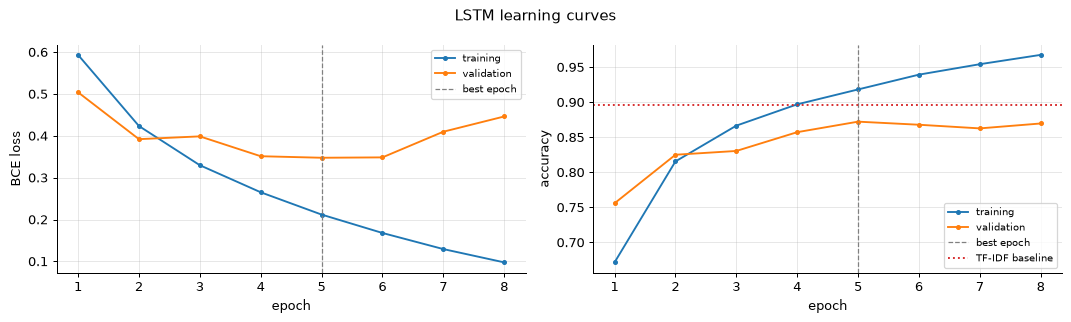

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ep = np.arange(1, len(hist_lstm["train_loss"]) + 1)
for ax, key, name in [(axes[0], "loss", "BCE loss"), (axes[1], "acc", "accuracy")]:
    ax.plot(ep, hist_lstm[f"train_{key}"], "o-", ms=3, label="training")
    ax.plot(ep, hist_lstm[f"val_{key}"], "o-", ms=3, label="validation")
    ax.axvline(hist_lstm["best_epoch"] + 1, color="gray", ls="--", lw=1, label="best epoch")
    ax.set_xlabel("epoch"); ax.set_ylabel(name)
axes[1].axhline(acc_bow_val, color="C3", ls=":", label="TF-IDF baseline")
for ax in axes: ax.legend(fontsize=8)
fig.suptitle("LSTM learning curves"); plt.tight_layout(); plt.show()

The LSTM overfits quickly: after epoch 5 the training accuracy keeps climbing (97% at epoch 8) while the validation loss goes up. With 640,000 embedding parameters and 20,000 reviews, the model can memorise the training set. Patience stopped the run at epoch 8 and restored epoch 5. Its best validation accuracy, 87.2%, is still below the TF-IDF baseline (89.6%).

## 6. Evaluation on the test set

All choices are made, so we evaluate once on the 25,000 test reviews, together with the TF-IDF baseline. Besides accuracy, the **ROC AUC** (from the logistic regression notes) measures how well the probabilities **rank** positive reviews above negative ones, independently of the 0.5 threshold.

In [8]:
from sklearn.metrics import roc_auc_score, classification_report

test_loss, test_acc, p_te = evaluate(lstm_model, test_loader)
p_bow_te = logreg.predict_proba(tfidf.transform(seqs_te))[:, 1]
print(f"LSTM          test accuracy {test_acc:.4f}   ROC AUC {roc_auc_score(y_te, p_te):.4f}")
print(f"TF-IDF + LR   test accuracy {np.mean((p_bow_te > 0.5) == y_te):.4f}   ROC AUC {roc_auc_score(y_te, p_bow_te):.4f}\n")
pred_te = (p_te > 0.5).astype(int)
print(classification_report(y_te, pred_te, target_names=class_names, digits=3))

LSTM          test accuracy 0.8661   ROC AUC 0.9349
TF-IDF + LR   test accuracy 0.8833   ROC AUC 0.9534

              precision    recall  f1-score   support

    Negative      0.858     0.877     0.868     12500
    Positive      0.875     0.855     0.865     12500

    accuracy                          0.866     25000
   macro avg      0.866     0.866     0.866     25000
weighted avg      0.866     0.866     0.866     25000



On the test set the LSTM is about 1.7 points below TF-IDF, and its probabilities rank the reviews a little worse (ROC AUC 0.935 against 0.953). With two balanced classes, precision and recall tell the same story as the accuracy.

**The most confident mistakes.** Reading the errors is the best way to understand a model:

In [9]:
wrong = np.where(pred_te != y_te)[0]
for rank, i in enumerate(wrong[np.argsort(np.abs(p_te[wrong] - 0.5))[::-1][:3]]):
    print(f"[{rank + 1}] predicted {class_names[pred_te[i]]} with P(positive) = {p_te[i]:.3f}, labelled {class_names[y_te[i]]}")
    print("    ..." + decode(seqs_te[i][-T:])[-500:], "\n")

[1] predicted Positive with P(positive) = 1.000, labelled Negative
    ...re seen before in the tv series now if you saw the movie first rather than the series you would get a different feeling about it then the series fan br br saying that leonard is definitely on top form and makes the movie just like in the tv series the film has recently had a new <UNK> of life on dvd and is usually on <UNK> over a quiet weekend it is a cracking good film but for fans you may feel that <UNK> seen it similarly before br br saying that though its worth a buying watching br br 7 8 10 

[2] predicted Positive with P(positive) = 1.000, labelled Negative
    ...s a good choice to leave it <UNK> rather than <UNK> <UNK> it up br br taut and suspenseful throughout strange fruit is a hugely ambitious debut and i have high hopes for what the writer director kyle will <UNK> next he and his colleagues are a talent worth watching br br i hope strange fruit gets a wider release soon as more people deserve to see 

Read them carefully. The first two praise the film ("on top form", "a talent worth watching"), yet they are labelled negative. In IMDB, negative means a rating of 4/10 or less, so these are probably **labelling errors**, and the model is right. The third one is a genuine mistake: a long, friendly anecdote that ends with "the dumbest movie ever made". Every real dataset has some wrong labels, and a model's most confident errors are the best place to find them.

## 7. Is word order worth modelling?

We train three more models with the same loop and compare them on the **validation** set:
- a **plain RNN** (`nn.RNN`): no gates;
- a **GRU** (`nn.GRU`): a lighter gated network with two gates instead of three;
- the **mean of the word embeddings** followed by a linear layer: a neural network that, like TF-IDF, **ignores the order** of the words.

plain RNN            val acc 0.7826   best epoch 5   (37 s)


GRU                  val acc 0.8798   best epoch 3   (28 s)


mean of embeddings   val acc 0.8836   best epoch 5   (10 s)


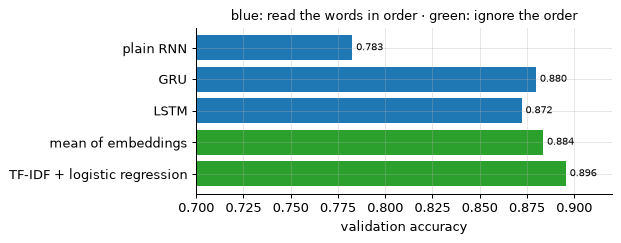

In [10]:
class MeanEmbedding(nn.Module):
    """Average the embeddings of the real tokens, then a linear layer. Ignores word order."""
    def __init__(self, vocab_size=V, embedding_dim=64):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=PAD)
        self.fc = nn.Linear(embedding_dim, 1)

    def forward(self, x, lengths):
        mean = self.embedding(x).sum(1) / lengths.to(x.device).unsqueeze(1).float()   # the pads are zero vectors
        return self.fc(mean).squeeze(1)

results = {"TF-IDF + logistic regression": acc_bow_val, "LSTM": hist_lstm["val_acc"][hist_lstm["best_epoch"]]}
for name, make in [("plain RNN", lambda: SentimentRNN(cell="rnn")), ("GRU", lambda: SentimentRNN(cell="gru")),
                   ("mean of embeddings", lambda: MeanEmbedding())]:
    torch.manual_seed(0)
    m = make()
    t0 = time.time()
    h = fit(m, train_loader, val_loader, verbose=False)
    results[name] = h["val_acc"][h["best_epoch"]]
    print(f"{name:<20} val acc {results[name]:.4f}   best epoch {h['best_epoch'] + 1}   ({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(7, 2.8))
names = ["plain RNN", "GRU", "LSTM", "mean of embeddings", "TF-IDF + logistic regression"]
colors = ["C0", "C0", "C0", "C2", "C2"]
ax.barh(names[::-1], [results[n] for n in names][::-1], color=colors[::-1])
for yi, n in enumerate(names[::-1]): ax.text(results[n] + 0.002, yi, f"{results[n]:.3f}", va="center", fontsize=8)
ax.set_xlim(0.7, 0.92); ax.set_xlabel("validation accuracy")
ax.set_title("blue: read the words in order · green: ignore the order", fontsize=10)
plt.tight_layout(); plt.show()

**What the comparison says.**
- **The gates matter.** The plain RNN is far behind (78%): over 200 steps its gradients vanish, so it cannot connect the prediction to the words that matter. The LSTM and the GRU are close (87 to 88%); the GRU is a little cheaper.
- **The order-free models are as good or better.** The mean of the embeddings (88%) and TF-IDF (almost 90%) are at the top, and they train in a fraction of the time. For sentiment, *which* words appear matters much more than their order, and 20,000 reviews are not enough for a network trained from scratch to learn more than that. TF-IDF also has an advantage: it reads the whole review, while the networks read only the last 200 tokens (43% of the reviews are cut). The mean of embeddings reads the same 200 tokens as the LSTM, so it is the fair comparison: 88% against 87%.

This is a common and important lesson: always compare with a simple baseline. Sequence models shine when the order is essential, or when they are pre-trained on huge amounts of text: pre-trained transformers reach about 95% on IMDB.

## 8. Your own reviews

To classify new text, it must go through **exactly the same pre-processing** as the training data: lower case, remove punctuation, split into words, map to indices with the same vocabulary (unknown words become `<UNK>`), and add `<START>`. We compare the LSTM with TF-IDF on a few sentences, including negations, where word order matters.

In [11]:
def text_to_ids(text):
    words = re.findall(r"[a-z0-9']+", text.lower().replace("<br />", " "))
    return [START] + [word_index.get(w, UNK) if word_index.get(w, UNK) < V else UNK for w in words]

def predict_lstm(text):
    ids = text_to_ids(text)[-T:]
    lstm_model.eval()
    with torch.no_grad():
        return torch.sigmoid(lstm_model(torch.tensor(ids)[None].to(device), torch.tensor([len(ids)]))).item()

def predict_bow(text):
    return logreg.predict_proba(tfidf.transform([np.array(text_to_ids(text))]))[0, 1]

reviews = [
    "this was a terrible film with too much violence i walked out halfway through",
    "one of the best movies i have seen in years , brilliant acting and a beautiful story",
    "the movie was not good at all",
    "the movie was not bad at all",
    "at first i thought it would be boring , but it turned out to be wonderful",
    "great actors , great director , great budget , and still a complete waste of time",
]
print(f"{'P(positive)':>12}")
print(f"{'LSTM':>6}{'TF-IDF':>8}   review")
for r in reviews:
    print(f"{predict_lstm(r):>6.2f}{predict_bow(r):>8.2f}   {r}")

 P(positive)
  LSTM  TF-IDF   review
  0.01    0.00   this was a terrible film with too much violence i walked out halfway through
  0.99    1.00   one of the best movies i have seen in years , brilliant acting and a beautiful story
  0.21    0.30   the movie was not good at all
  0.07    0.00   the movie was not bad at all
  0.43    0.35   at first i thought it would be boring , but it turned out to be wonderful
  0.04    0.86   great actors , great director , great budget , and still a complete waste of time


Clear reviews are easy for both models. **Negation** is hard: "not good" and "not bad" contain almost the same words, and both models call both sentences negative. The "at first I thought it would be boring, but..." review fools both of them too. The LSTM could in principle use the order, but it was trained on long reviews, where a negation is one signal among many. The order does help the LSTM in the last sentence: TF-IDF counts three "great" and says positive, while the LSTM gives the final clause the last word.

Try your own sentences. Very short sentences are unlike the training reviews (median length about 180 tokens), so both models can be unreliable on them.

## 9. Summary and practical tips

- Text is a variable-length sequence of tokens. A **vocabulary** maps words to indices, with special tokens for padding, start and unknown words.
- **`nn.Embedding`** turns each index into a learned vector; **`nn.LSTM`** reads the vectors in order and keeps a memory; a **linear** layer on the last hidden state gives the prediction.
- Gated networks (LSTM, GRU) learn from long sequences; a plain RNN does not, because its gradients vanish.
- For sentiment, **which** words appear matters much more than their order. An LSTM trained from scratch on 20,000 reviews does not beat a bag of words. Sequence models pay off when order is essential (translation, speech, time series) or when they are **pre-trained** on huge amounts of text, which leads to the transformers of the next chapter (about 95% on IMDB).

**Tips that carry over:**
- **Build a simple baseline first** (TF-IDF + logistic regression for text). A complex model has to beat it to be worth it.
- **Pre-process new text exactly like the training text**: same tokeniser, same vocabulary, same special tokens.
- **Handle padding**: give the lengths to `pack_padded_sequence` (or pad at the start), so the model does not read the pads.
- **Truncation is a modelling choice**: here the end of a review is more informative than the beginning.
- **Clip the gradients** of recurrent networks, and use **early stopping**: with 640,000 embedding parameters, the model overfits after a few epochs.
- **Read the most confident errors**: they reveal what the model gets wrong, and sometimes errors in the labels.

## Exercises

Try each one before opening the answer.

1. **Which tokens to keep.** Change `to_tensors` to keep the **first** 200 tokens instead of the last 200, and train the LSTM again. What happens to the validation accuracy, and why?
2. **Padding.** Replace `lengths` by a tensor full of $T = 200$ when you call the trained model on short reviews, so that the LSTM also reads the padding. How do the predictions change?
3. **Improving the LSTM.** Propose three changes that could make the LSTM beat the TF-IDF baseline.

<details>
<summary><b>Answers</b></summary>

**1.** It drops by about 2 points (the extended lab measures 87.0% with the last 200 tokens, 84.8% with the first 200 and 80.7% with the first 100). 43% of the reviews are longer than 200 tokens, and reviewers often state their verdict at the end ("overall, 8/10"), so the end of a long review is more informative than its plot summary at the start.

**2.** The model then updates its memory on dozens or hundreds of `<PAD>` steps after the real review. The final state drifts away from the one after the last real word, the probabilities change, and the accuracy on short reviews drops (the extended lab measures 86.8% → 84.5% on reviews shorter than 60 tokens). Padding at the start, or packing with the true lengths, avoids this.

**3.** Some options: use **pre-trained word embeddings** (GloVe, word2vec) instead of learning 640,000 parameters from 20,000 reviews; use **longer sequences** (truncation throws away part of 43% of the reviews); classify from the **mean or maximum of all hidden states** instead of the last one; add **regularisation** (dropout on the embeddings, weight decay), since the model overfits after about 5 epochs; or fine-tune a **pre-trained transformer**, which is what modern systems do.

</details>

## Going further: the extended lab

The extended version of this lab trains the same models and adds:
- review lengths, Zipf's law and the coverage of the vocabulary;
- embeddings as a linear layer on one-hot vectors;
- the **RNN** and the **LSTM** written from scratch and checked against PyTorch; **backpropagation through time** and why gradients vanish; why the LSTM's cell state lets them survive;
- packing measured, accuracy by review length, and more experiments (bidirectional LSTM, first vs last tokens);
- inside the models: word polarities, nearest neighbours in embedding space, and the LSTM reading a review word by word; and six exercises.

<a href="https://colab.research.google.com/github/imagra93/ML-course-labs/blob/main/notebooks/neural_networks/lab 13 - LSTM sentiment analysis - extended.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> [lab 13 - LSTM sentiment analysis - extended.ipynb](lab%2013%20-%20LSTM%20sentiment%20analysis%20-%20extended.ipynb)